# 입력 saliency (Grad-CAM 류) — 어느 구간이 그 국적 예측을 끌어올렸나

frozen XLS-R + linear head 전체로 오디오를 forward하고, **클래스 logit을 입력 파형으로 backprop**해서
시간별 |gradient|(saliency)를 봅니다. "모델이 오디오의 어디를 보는가".

⚠️ 무거움: 26GB 인코더 로드(~67s) + GPU. 입력 gradient는 noisy하니 참고용.
⚠️ 우리 표현은 화자 지배적(t-SNE 참고)이라 saliency도 화자 특징 강한 구간을 가리킬 가능성.

In [1]:
import os, sys, json
import numpy as np, torch, torch.nn as nn, soundfile as sf, pandas as pd
from scipy import signal
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
sys.path.insert(0,"$HOME/scripts"); import baseline_common as bc
sys.path.insert(0,"$HOME")
from country_classifier.model import build_model
fm.fontManager.addfont("$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf")
plt.rcParams["font.family"]=fm.FontProperties(fname="$NATIONALITY_OUTPUTS/fonts/NotoSansKR.ttf").get_name()
plt.rcParams["axes.unicode_minus"]=False
DEV="cuda"; SR=16000

# 빠른 61-class linear head (캐시 feature, z-score)
MF="$NATIONALITY_RUNS/features_fine_811"
z=np.load(MF+"/train.npz",allow_pickle=True); Xtr=z["X"].astype(np.float32); ytr=z["y"].astype(np.int64)
label2id=json.load(open(MF+"/label2id.json",encoding="utf-8")); C=len(label2id)
mean=Xtr.mean(0,keepdims=True); std=Xtr.std(0,keepdims=True)+1e-6
Xt=torch.from_numpy((Xtr-mean)/std); yt=torch.from_numpy(ytr)
head=nn.Linear(1920,C).to(DEV); opt=torch.optim.AdamW(head.parameters(),lr=1e-3,weight_decay=1e-4); lf=nn.CrossEntropyLoss()
for ep in range(15):
    perm=torch.randperm(len(yt))
    for s in range(0,len(yt),8192):
        i=perm[s:s+8192]; opt.zero_grad(); lf(head(Xt[i].to(DEV)),yt[i].to(DEV)).backward(); opt.step()
meanT=torch.from_numpy(mean).to(DEV); stdT=torch.from_numpy(std).to(DEV)
Wt=head.weight.detach(); bt=head.bias.detach()
print("head trained")

head trained


In [2]:
# 인코더 로드 (~67s) + activation checkpointing 끄기(autocast backward 충돌 회피)
def disable_ckpt(enc):
    n=0
    for m in enc.modules():
        if hasattr(m,"precheckpoint_forward"): m.forward=m.precheckpoint_forward; n+=1
    return n
model=build_model(backend="fairseq_xlsr",num_classes=C,
                  checkpoint_path="$SPEECH_AI_MODELS/xlsr2_2B_1000k.pt",
                  fairseq_root="$FAIRSEQ_ROOT",freeze_encoder=True).to(DEV).eval()
print("ckpt off on",disable_ckpt(model.encoder),"modules")
try: model.encoder.encoder.layerdrop=0.0
except: pass
ridx=pd.read_csv("$NATIONALITY_DATA/reading_index.csv"); audio_idx=bc.build_audio_index(bc.DEFAULT_AUDIO_ROOT)
print("ready")

INFO:fairseq.tasks.text_to_speech:Please install tensorboardX: pip install tensorboardX
$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/torch/nn/utils/weight_norm.py:30: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


ckpt off on 48 modules
ready


$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/torch/nn/modules/conv.py:306: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv1d(input, weight, bias, self.stride,
DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.pyplot:Loaded backend module://matplotlib_inline.backend_inline version unknown.
DEBUG:matplotlib.font_manager:findfont: Matching Noto Sans KR:style=normal:variant=normal:weight=normal:stretch=normal:size=10.0.
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/lib/python3.8/site-packages/matplotlib/mpl-data/fonts/ttf/STIXNonUniBolIta.ttf', name='STIXNonUnicode', style='italic', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
DEBUG:matplotlib.font_manager:findfont: score(FontEntry(fname='$HOME/miniconda3/envs/fairseq_xlsr/

중국어 발화 CN56RA132_CN0452_20211015.wav | 모델 top1 예측: 중국어


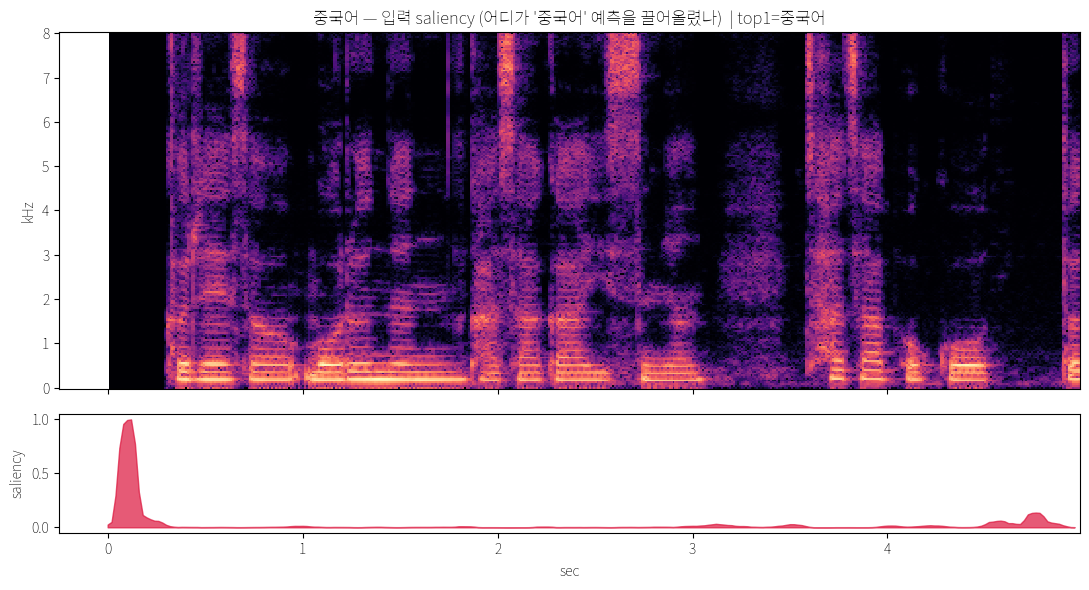

In [3]:
def saliency(path, target_label, crop=5.0):
    y,s=sf.read(path); y=(y.mean(1) if y.ndim>1 else y).astype(np.float32)[:int(crop*SR)]
    wav=torch.from_numpy(y)[None,:].to(DEV).requires_grad_(True)
    mask=torch.zeros(1,wav.shape[1],dtype=torch.bool,device=DEV)
    with torch.autocast("cuda"):
        f,fmask=model._extract_features(wav,mask); pool=model._pool(f,fmask)
        logit=((pool-meanT)/stdT)@Wt.T+bt
    model.zero_grad();
    if wav.grad is not None: wav.grad=None
    logit[0,label2id[target_label]].backward()
    sal=wav.grad[0].abs().float().cpu().numpy()
    pred=list(label2id)[int(logit.argmax())]
    return y, sal, pred

# ===== 선택 =====
NATION="중국어"; SEED=0; CROP=5.0
# ================
r=ridx[ridx.mother_tongue==NATION].sample(1,random_state=SEED).iloc[0]
y,sal,pred=saliency(audio_idx[r.fileName], NATION, CROP)
print(f"{NATION} 발화 {r.fileName} | 모델 top1 예측: {pred}")

f_,t_,Sxx=signal.spectrogram(y,fs=SR,nperseg=400,noverlap=240); m=f_<=8000
win=int(SR*0.02)                       # 20ms 프레임 평균 + 약간 smooth
sfr=np.array([sal[i:i+win].mean() for i in range(0,len(sal)-win,win)])
k=np.ones(5)/5; sfr=np.convolve(sfr,k,mode="same"); ts=np.arange(len(sfr))*0.02
sfr=sfr/(sfr.max()+1e-9)
fig,axs=plt.subplots(2,1,figsize=(11,6),sharex=True,gridspec_kw={"height_ratios":[3,1]})
axs[0].pcolormesh(t_,f_[m]/1000,10*np.log10(Sxx[m]+1e-10),shading="auto",cmap="magma")
axs[0].set_ylabel("kHz"); axs[0].set_title(f"{NATION} — 입력 saliency (어디가 '{NATION}' 예측을 끌어올렸나)  | top1={pred}")
axs[1].fill_between(ts,sfr,color="crimson",alpha=.7); axs[1].set_ylabel("saliency"); axs[1].set_xlabel("sec")
plt.tight_layout(); plt.show()

## 참고
- `NATION`/`SEED` 바꿔 다른 국적·발화 확인.
- 입력 gradient saliency는 **noisy**(onset 스파이크 등). gradient×input, integrated gradients, SmoothGrad로 개선 가능.
- t-SNE에서 본 대로 표현이 화자 지배적이라, saliency 해석은 신중히.